# SMT × MemUP на MQAR (Zoology, без шума) — ноутбук 03

**Статус.** Подготовлены код, проверки, аудит данных и отбора ответов, оценка стоимости для нескольких конфигураций MQAR. **Ничего не обучалось**: все расчёты ниже выполнены на CPU без моделей, кроме технических проверок на крошечных моделях. Фазы обучения в конце ноутбука выключены. Перед ними нужно выбрать конфигурацию (раздел 7) и разрешить короткий замер на GPU (раздел 6).

Stack Operations — в ноутбуке `02_smt_memup_stack.ipynb`. Этот ноутбук его не трогает: код MQAR лежит в отдельном `smt_memup_mqar.py`, а общие части (отбор top-K, нормировка дополнительного loss, детекторы, статистика) импортируются из `smt_memup_stack.py` без изменений.

Графики и таблицы этого ноутбука записываются в `outputs_mqar/`.

## 0. Что согласовано и что выбрано нами

* **Согласовано с научником:** MQAR из Zoology как задача поиска по ключу; без шума; к исходному SMT loss добавляется MemUP-подобное слагаемое; Stack Operations — вторая задача; MNIST позже.
* **Наш выбор (требует решения до обучения):** конфигурация MQAR (словарь, длина, число пар), K, окно локального детектора r (на MQAR — по правилу из раздела 5.1; число 8 в Stack — тоже наш выбор, из ноутбука 01, научник его не задавал), подвыборка моментов t для длинных последовательностей, размеры моделей, бюджеты, пороги проверки baseline.
* Протокол сравнения тот же, что для Stack (`preregistration.md` в 02): baseline / uniform / random-K / surprise-K — основное сравнение; score по входам декодера и oracle — вторичная диагностика; одинаковая сетка α; три seeds; test один раз.

## 1. Окружение
То же, что для 02: `/mem/envs/smt-memup`, ядро «Python (smt-memup)». Все ячейки до раздела 6 работают на CPU и GPU не занимают.

In [1]:
import sys, json, subprocess, importlib
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path("/mem/work")
sys.path.insert(0, str(ROOT))
import smt_memup_stack as S
import smt_memup_mqar as Q
importlib.reload(S); importlib.reload(Q)

CPU = S.setup_runtime(threads=4, device="cpu")       # analysis below never touches the shared GPU
S.sources(ROOT); Q.zoology_generator(ROOT)
OUT = ROOT / "outputs_mqar"; OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("code sha256: mqar", Q.code_sha256()[:16], "| stack", S.code_sha256()[:16], "| zoology", Q.ZOOLOGY_REVISION[:12])

INK, MUTED = "#0b0b0b", "#52514e"
CONFIG_COLOR = dict(zoology_basic="#2a78d6", pilot01="#eb6834", zoology_64="#1baf7a", zoology_128="#eda100",
                    zoology_256="#e87ba4", zoology_256_kv64="#008300")
RULE_COLOR = {"random-K": "#eb6834", "surprise-K (окно r)": "#1baf7a", "surprise-K (входы декодера)": "#eda100", "oracle": "#e87ba4"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": .8, "lines.linewidth": 2, "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "figure.dpi": 120,
                     "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(OUT / f"{name}.png"); plt.show()

code sha256: mqar 862c328cfb3815a9 | stack f0552c463cb2a4c3 | zoology 1ad20d193b61


## 2. Данные: генератор Zoology и что мы к нему добавляем

Вызываем `zoology.data.multiquery_ar` (commit `1ad20d1`) с `random_non_queries=False` — без шума. Последовательность: сначала N пар «ключ значение», затем N запросов — каждый ключ ровно один раз, между запросами токен-заполнитель 0. Ответ стоит на позиции запроса: прочитав ключ, модель называет его значение. Расстояние между запросами задаёт степенной закон (`power_a=0.01`), как у авторов.

Наше: только перевод `-100 → -1` и разметка, где записано значение для каждого запроса (`source_pos`, давность). Разметка нужна для аудита, групп метрик и oracle-контроля; в модель и в основной отбор она не попадает (проверено тестом).

In [2]:
cfg = Q.candidate("zoology_basic")
ex = Q.sample_mqar(cfg, 1, 7)
names = []
for t, (tok, yy) in enumerate(zip(ex["x"][0].tolist(), ex["y"][0].tolist())):
    kind = ("ключ" if t % 2 == 0 else "значение") if t < 2 * cfg.num_kv_pairs else ("запрос" if yy != -1 else "заполнитель")
    names.append(dict(t=t, токен=tok, роль=kind, ответ="" if yy == -1 else yy,
                      значение_записано_на=("" if yy == -1 else int(ex["source_pos"][0, t])),
                      давность=("" if yy == -1 else int(ex["delay"][0, t]))))
example = pd.DataFrame(names)
display(example[(example.роль != "заполнитель")])
example.to_csv(OUT / "table_example_sequence.csv", index=False)

,t,токен,роль,ответ,значение_записано_на,давность
0,0,127,ключ,,,
1,1,208,значение,,,
2,2,108,ключ,,,
3,3,172,значение,,,
4,4,33,ключ,,,
5,5,131,значение,,,
6,6,46,ключ,,,
7,7,151,значение,,,
8,8,33,запрос,131,5,3
10,10,46,запрос,151,7,3


### 2.1. Кандидаты

| имя | словарь | длина | пар N | K | откуда |
|---|---:|---:|---:|---:|---|
| zoology_basic | 256 | 64 | 4 | 1 | базовый пример Zoology (`examples/basic.py`) |
| pilot01 | 128 | 64 | 8 | 2 | наш пилот версии 01 |
| zoology_64 | 8192 | 64 | 4 | 1 | основной sweep Zoology без шума, первая настройка |
| zoology_128 | 8192 | 128 | 8 | 2 | основной sweep Zoology |
| zoology_256 | 8192 | 256 | 16 | 4 | основной sweep Zoology |
| zoology_256_kv64 | 8192 | 256 | 64 | 16 | самая трудная обучающая настройка sweep |

В sweep Zoology обучение идёт на смеси этих длин: 100 тыс. примеров (64/4) и по 20 тыс. остальных, 32 эпохи, batch 256. Мы берём одну настройку за раз. **K = N/4** — наш выбор: при K ≥ N любой отбор берёт все будущие ответы, и surprise-K, random-K и uniform совпадают.

,конфигурация,словарь,длина,пар,K,answers_per_sequence,delay_median,delay_p95,long_fraction,pair_inside_last_r_tokens,anchors_inside_written_prefix,anchors_with_future_answers,mean_pool,anchors_pool_gt_K,chance_structured,chance_vocab
0,zoology_basic,256,64,4,1,4,13.0,49.0,0.431,0.526,0.125,0.605,2.240,0.610,0.250,0.008
1,pilot01,128,64,8,2,8,19.0,49.0,0.382,0.572,0.250,0.874,4.600,0.679,0.125,0.016
2,zoology_64,8192,64,4,1,4,13.0,49.0,0.420,0.540,0.125,0.605,2.291,0.635,0.250,0.000
3,zoology_128,8192,128,8,2,8,25.0,103.0,0.411,0.559,0.125,0.749,3.775,0.573,0.125,0.000
4,zoology_256,8192,256,16,4,16,49.0,203.0,0.404,0.588,0.125,0.859,6.666,0.533,0.062,0.000
5,zoology_256_kv64,8192,256,64,16,64,123.0,193.0,0.440,0.530,0.500,0.996,48.188,0.875,0.016,0.000


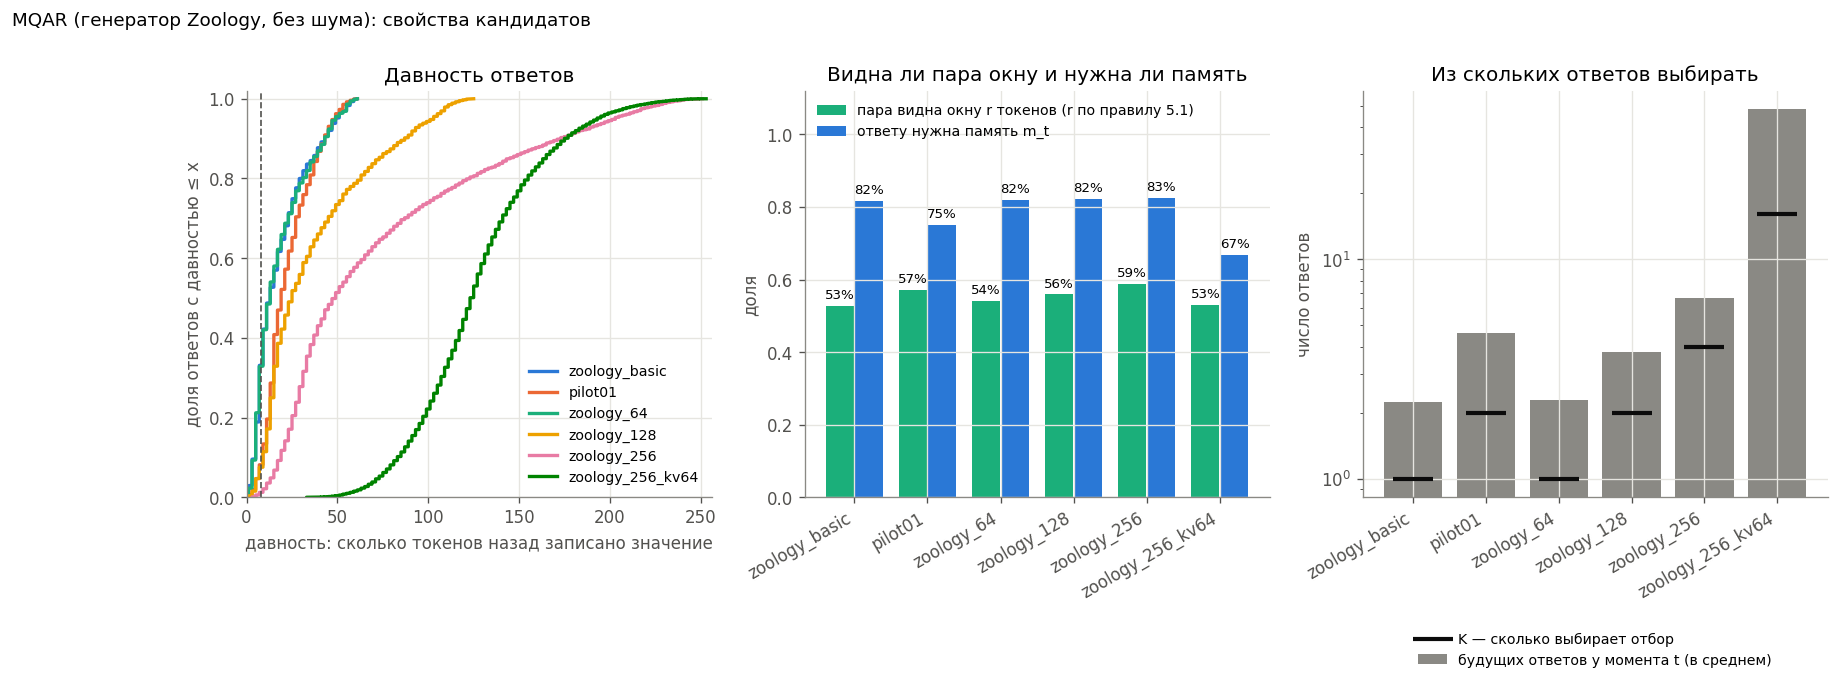

In [3]:
rows = []
data = {}
for name in Q.CANDIDATES:
    c = Q.candidate(name)
    data[name] = Q.sample_mqar(c, 256, S.derive_seed(512, 0))
    rows.append(dict(конфигурация=name, словарь=c.vocab, длина=c.seq_len, пар=c.num_kv_pairs, K=c.K, **Q.data_audit(data[name], c)))
audit = pd.DataFrame(rows)
audit.to_csv(OUT / "table_data_audit.csv", index=False)
display(audit.drop(columns=["sequences", "unique_sequences", "answers"]).round(3))

# memory need per (moment t, answer) pair, from the generator metadata (audit only)
pair_rows = []
for name, b in data.items():
    w = S.windows(S.slice_batch(b, 0, 64))
    v = w["valid"]
    pair_rows.append(dict(конфигурация=name, нужна_память=float(w["prefix"][v].float().mean())))
pairs_tab = pd.DataFrame(pair_rows)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for name, b in data.items():
    d = np.sort(b["delay"][b["target_mask"]].numpy())
    ax[0].plot(d, np.arange(1, len(d) + 1) / len(d), color=CONFIG_COLOR[name], label=name)
ax[0].axvline(8, color=MUTED, ls="--", lw=1)
ax[0].set(title="Давность ответов", xlabel="давность: сколько токенов назад записано значение",
          ylabel="доля ответов с давностью ≤ x", ylim=(0, 1.02), xlim=(0, 256))
ax[0].legend(fontsize=8.5, loc="lower right")
x = np.arange(len(audit))
ax[1].bar(x - .2, audit.pair_inside_last_r_tokens, .38, color="#1baf7a", label="пара видна окну r токенов (r по правилу 5.1)")
ax[1].bar(x + .2, pairs_tab.нужна_память, .38, color="#2a78d6", label="ответу нужна память m_t")
for i in x:
    ax[1].text(i - .2, audit.pair_inside_last_r_tokens[i] + .02, f"{audit.pair_inside_last_r_tokens[i]:.0%}", ha="center", fontsize=8)
    ax[1].text(i + .2, pairs_tab.нужна_память[i] + .02, f"{pairs_tab.нужна_память[i]:.0%}", ha="center", fontsize=8)
ax[1].set_xticks(x, audit.конфигурация, rotation=30, ha="right"); ax[1].set_ylim(0, 1.12)
ax[1].set(title="Видна ли пара окну и нужна ли память", ylabel="доля")
ax[1].legend(fontsize=8.5, loc="upper left")
ax[2].bar(x, audit.mean_pool, color="#8a8984", label="будущих ответов у момента t (в среднем)")
ax[2].scatter(x, audit.K, color=INK, zorder=3, marker="_", s=600, linewidths=2.5, label="K — сколько выбирает отбор")
ax[2].set_xticks(x, audit.конфигурация, rotation=30, ha="right")
ax[2].set(title="Из скольких ответов выбирать", ylabel="число ответов", yscale="log")
ax[2].legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(.5, -.3))
fig.suptitle("MQAR (генератор Zoology, без шума): свойства кандидатов", x=.01, y=1.03, ha="left", fontsize=11)
save(fig, "fig1_data")

**Что видно.**
* В MQAR почти каждому ответу нужна память m_t — значения записаны в начале, а вопросы идут после них. Исключение — моменты t внутри блока пар: их будущие ответы декодер может «подсмотреть» во входах. В Stack таких ответов было большинство (там нужна память только 22% пар), здесь — меньшинство.
* Окно в 8 токенов (как в Stack) почти никогда не содержит пару «ключ значение» для запроса: ≤ 21%, при длине ≥ 128 — почти 0. Поэтому окно для MQAR выбрано правилом из раздела 5.1, и при нём пару видно примерно у половины ответов (зелёные столбцы).
* При N = 4 у момента t в среднем ~2 будущих ответа: выбирать есть из чего только при K = 1.

## 3. Почему MemUP может помочь на MQAR и почему здесь это не гарантировано

**Аргумент «за».** Каждый ответ требует связать ключ из запроса со значением, записанным давно. Если SMT-обучение тратит сигнал равномерно, а связывание учится медленно (в пилоте 01 оно не выучилось вовсе), то дополнительный вес на ответах, которые невозможно получить без памяти, может ускорить обучение памяти.

**Ограничение, которое показывают данные.** MemUP выбирает ответы, неожиданные для локального предиктора. На MQAR почти всем ответам нужна память, поэтому выбор «память или нет» здесь мало что даёт; локальное окно может различать только «давние» и «недавние» ответы. С окном 8 (как в Stack) surprise-K на MQAR совпадает с random-K. С окном по правилу 5.1 он отличается, но скромно: даже идеальный детектор обогащает дальние ответы в 1,1–1,3 раза против ×2,9 в Stack. Значит, MQAR проверяет гипотезу слабее, чем Stack. Это стоит обсудить с научником **до** дорогих запусков.

## 4. Технические проверки (CPU, ~2 мин)

In [4]:
r = subprocess.run([sys.executable, str(ROOT / "checks/test_smt_memup_mqar.py")], capture_output=True, text=True, cwd=ROOT)
print("\n".join(l for l in r.stdout.splitlines() if l.startswith("OK") or "passed" in l))
assert r.returncode == 0, r.stderr[-3000:]

OK  Data: Zoology semantics (pairs, one query per pair, answer = written value, no noise), reproducible
OK  Same raw data as the direct Zoology call (only -100 -> -1)
OK  Encoder: trimmed chunked windows equal full padded windows (Stack code path)
OK  Decoder: logits at answer positions equal Teacher.decode
OK  SMT loss with all anchors = smt_memup_stack.smt_loss (MQAR and Stack batches, all deterministic variants)
OK  Random-K: E[L_selected] = L_dec; uniform = (1+alpha) L_dec; alpha=0 identical for all variants
OK  Anchor subset: only the requested windows are encoded; A = T reproduces the all-anchor loss
OK  Gradients: SMT reaches encoder and updater, not detectors; DMT readout never reaches updater; truncated DMT
OK  Selector uses no metadata: scrambling source/delay/key positions changes only the oracle
OK  Resume: crash in SMT and in DMT reproduces the uninterrupted run bit-exactly; identity mismatch refused
OK  Evaluation, retention probe, idealised-detector selection audit run a

Ключевые проверки:
* данные совпадают с прямым вызовом Zoology;
* **экономный forward при всех моментах t даёт тот же SMT loss, что Stack-модуль** — разница меньше 1e-4, на батчах MQAR и Stack;
* logits только в позициях ответов совпадают с `Teacher.decode`;
* metadata не попадает в отбор;
* resume посреди SMT и DMT воспроизводит результат бит в бит.

## 5. Каким ответам дополнительный loss даст вес (до обучения)

Обученных детекторов здесь нет — по согласованию сейчас ничего не обучаем. Вместо них **идеальные правила**:
* «окно r» знает ответ, если пара ключ–значение лежит в последних r токенах, иначе угадывает (r — по правилу 5.1);
* «входы декодера» знает ответ, если пара появилась после момента t.

Это верхняя граница того, что может сделать обученный детектор с таким входом. Если даже идеальное окно не отличается от random-K, обученное тоже не будет.

### 5.1. Окно локального детектора: откуда число

**Число 8 научник не задавал.** Оно пришло из ноутбука 01: там его выбрали для Stack (окно 8 и порог «дальнего ответа» 8), а потом перенесли на MNIST и на пилот MQAR. Для MQAR оно не подходит.

Что делает окно на MQAR. Детектор знает ответ, если пара ключ–значение попала в последние r токенов.
* Слишком маленькое окно почти никогда не видит пару: все ответы одинаково «неожиданны».
* Слишком большое видит всегда: тоже никакого различия.

Правило, заданное до обучения и зависящее только от данных: **наименьшее r из сетки, при котором пара видна окну хотя бы у половины ответов**. Тогда окно делит ответы примерно пополам. «Дальний ответ» = давность ≥ r, как в Stack. График ниже — для идеального детектора, без обучения.

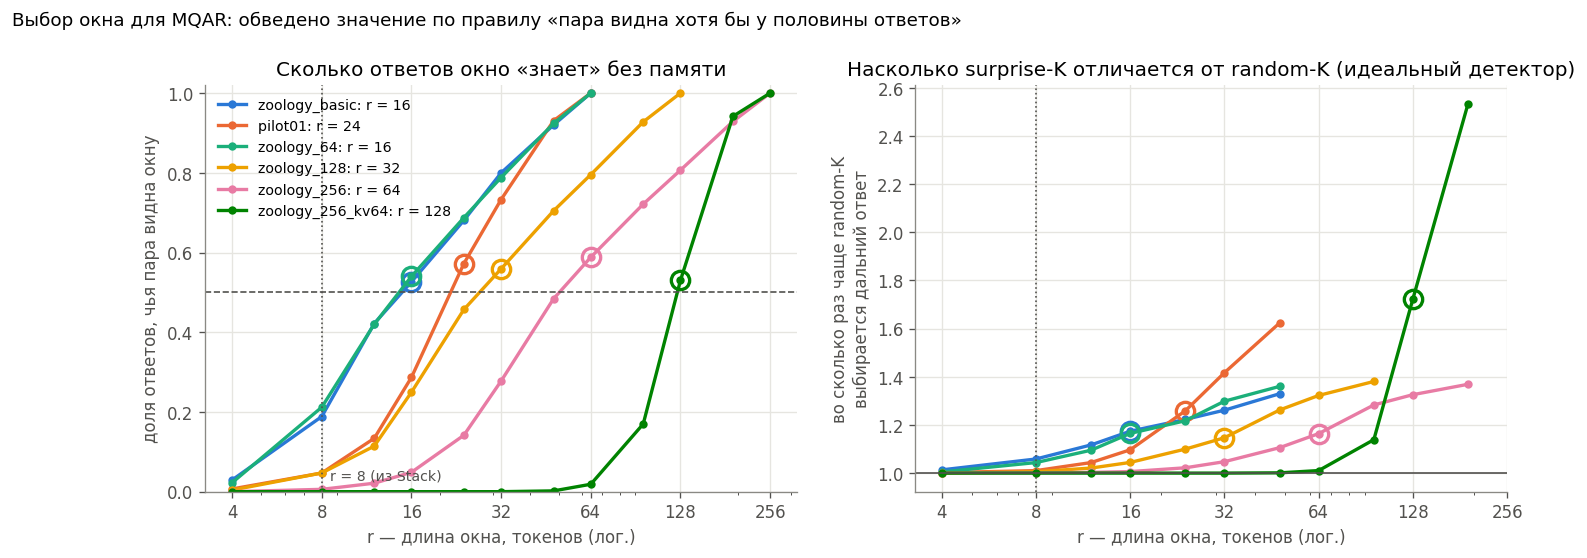

конфигурация,pilot01,zoology_128,zoology_256,zoology_256_kv64,zoology_64,zoology_basic
r,,,,,,
4,0.01,0.00,0.00,0.00,0.02,0.03
8,0.05,0.05,0.01,0.00,0.21,0.19
12,0.13,0.11,0.02,0.00,0.42,0.42
16,0.29,0.25,0.05,0.00,0.54,0.53
24,0.57,0.46,0.14,0.00,0.69,0.68
32,0.73,0.56,0.28,0.00,0.79,0.80
48,0.93,0.70,0.48,0.00,0.92,0.92
64,1.00,0.80,0.59,0.02,1.00,1.00
96,NaN,0.93,0.72,0.17,NaN,NaN


In [5]:
sweeps = []
for name, b in data.items():
    t = Q.window_sweep(Q.candidate(name), b); t["конфигурация"] = name; sweeps.append(t)
sweep = pd.concat(sweeps, ignore_index=True)
sweep.to_csv(OUT / "table_window_sweep.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for name in Q.CANDIDATES:
    t = sweep[sweep.конфигурация == name]; r0 = Q.candidate(name).local_window
    ax[0].plot(t.r, t.pair_visible, marker="o", ms=4, color=CONFIG_COLOR[name], label=f"{name}: r = {r0}")
    ax[0].plot([r0], [float(t[t.r == r0].pair_visible.iloc[0])], marker="o", ms=11, mfc="none", mec=CONFIG_COLOR[name], mew=2)
    ax[1].plot(t.r, t.lift, marker="o", ms=4, color=CONFIG_COLOR[name])
    ax[1].plot([r0], [float(t[t.r == r0].lift.iloc[0])], marker="o", ms=11, mfc="none", mec=CONFIG_COLOR[name], mew=2)
ax[0].axhline(.5, color=MUTED, ls="--", lw=1); ax[0].axvline(8, color=MUTED, ls=":", lw=1)
ax[0].text(8.5, .03, "r = 8 (из Stack)", color=MUTED, fontsize=8.5)
ax[0].set(xscale="log", xlabel="r — длина окна, токенов (лог.)", ylabel="доля ответов, чья пара видна окну",
          title="Сколько ответов окно «знает» без памяти", ylim=(0, 1.02))
ax[0].set_xticks([4, 8, 16, 32, 64, 128, 256], ["4", "8", "16", "32", "64", "128", "256"])
ax[0].legend(fontsize=8.5, loc="upper left")
ax[1].axhline(1, color=MUTED, lw=1); ax[1].axvline(8, color=MUTED, ls=":", lw=1)
ax[1].set(xscale="log", xlabel="r — длина окна, токенов (лог.)",
          ylabel="во сколько раз чаще random-K\nвыбирается дальний ответ", title="Насколько surprise-K отличается от random-K (идеальный детектор)")
ax[1].set_xticks([4, 8, 16, 32, 64, 128, 256], ["4", "8", "16", "32", "64", "128", "256"])
fig.suptitle("Выбор окна для MQAR: обведено значение по правилу «пара видна хотя бы у половины ответов»", x=.01, y=1.02, ha="left", fontsize=11)
save(fig, "fig2b_window")
display(sweep.pivot(index="r", columns="конфигурация", values="pair_visible").round(2))

правило,random-K,surprise-K (окно r),surprise-K (входы декодера),oracle
конфигурация,,,,
zoology_basic,0.897,0.907,0.944,1.0
pilot01,0.844,0.849,0.937,1.0
zoology_64,0.897,0.891,0.951,1.0
zoology_128,0.905,0.903,0.963,1.0
zoology_256,0.909,0.909,0.970,1.0
zoology_256_kv64,0.733,0.792,0.928,1.0


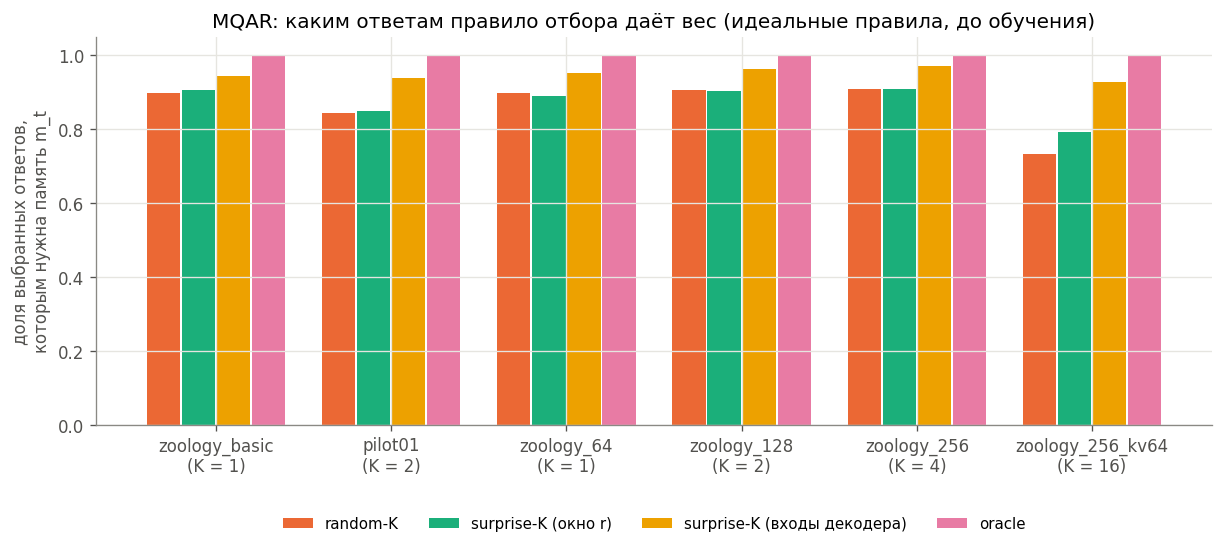

In [6]:
sel_rows = []
for name, b in data.items():
    c = Q.candidate(name)
    sel = S.selection_audit(S.slice_batch(b, 0, 64), c, {"window": Q.IdealWindow(c), "context": Q.IdealContext(c)}, CPU)
    sel["конфигурация"] = name; sel["K"] = c.K
    sel_rows.append(sel[sel.anchors == "all anchors"])
selection = pd.concat(sel_rows, ignore_index=True)
selection.to_csv(OUT / "table_selection_audit_ideal.csv", index=False)
rule_name = {"random_k (exact expectation)": "random-K", "surprise_k": "surprise-K (окно r)",
             "surprise_ctx_k": "surprise-K (входы декодера)", "oracle_prefix_k": "oracle"}
tab = selection[selection.rule.isin(rule_name)].assign(правило=lambda d: d.rule.map(rule_name))
pivot = tab.pivot(index="конфигурация", columns="правило", values="memory_dependent").reindex(list(Q.CANDIDATES))[list(rule_name.values())]
display(pivot.round(3))
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(pivot)); wdt = .2
for i, rn in enumerate(pivot.columns):
    ax.bar(x + (i - 1.5) * wdt, pivot[rn], wdt * .95, color=RULE_COLOR[rn], label=rn)
ax.set_xticks(x, [f"{n}\n(K = {Q.candidate(n).K})" for n in pivot.index])
ax.set(ylim=(0, 1.05), ylabel="доля выбранных ответов,\nкоторым нужна память m_t",
       title="MQAR: каким ответам правило отбора даёт вес (идеальные правила, до обучения)")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(.5, -.2), ncol=4)
save(fig, "fig2_selection")

**Вывод аудита:** доля ответов, которым нужна память, почти не различает правила — random-K и так выбирает в основном такие. Окно r меняет другое: какие из них давние (раздел 5.1). Отличие по памяти дают только «входы декодера» и oracle.

## 6. Влезет ли: стоимость каждой конфигурации

**Точные счётчики работы** на один шаг SMT (batch 32) считаются без модели — так, как их обрабатывает код:
* число и длина окон энкодера;
* строки декодера;
* элементы матриц внимания;
* logits только в позициях ответов.

**Оценка памяти и времени** получена масштабированием **измеренного** шага Stack (RTX 5090: 0,10 с и 7,7 ГБ при 85 млн элементов внимания). Это грубая оценка до замера: она не учитывает различий в константах. DMT оценивается по измеренным 0,52 с на 64 последовательных шага RNN.

,конфигурация,моменты_t,batch,encoder_windows,answer_logits,оценка_пик_ГБ,оценка_с_на_шаг_SMT,оценка_с_на_шаг_DMT
0,zoology_basic,все,32,2048,3248,3.08,0.03,0.52
1,zoology_basic,все,16,1024,1576,2.10,0.03,0.52
2,zoology_basic,32,32,1526,1592,2.39,0.03,0.52
3,zoology_basic,32,16,760,783,1.65,0.03,0.52
4,zoology_basic,16,32,892,790,1.67,0.03,0.52
5,zoology_basic,16,16,447,394,1.34,0.03,0.52
6,pilot01,все,32,2048,8234,3.41,0.04,0.52
7,pilot01,все,16,1024,4134,2.16,0.03,0.52
8,pilot01,32,32,1526,4037,2.50,0.03,0.52
9,pilot01,32,16,760,2046,1.76,0.03,0.52


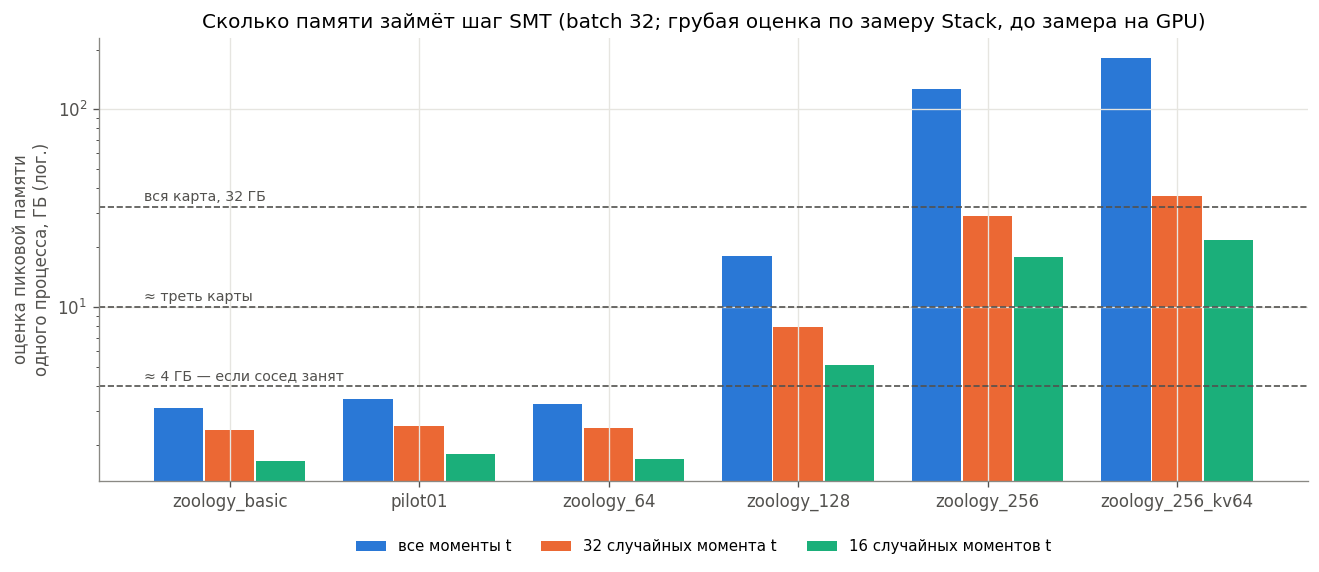

In [7]:
REF_ATT, REF_MIB, REF_S, REF_DMT_S = 2 * 2048 * 72 * 72 * 4, 7733, 0.100, 0.524
cost_rows = []
for name in Q.CANDIDATES:
    for A in (0, 32, 16):
        for bs in (32, 16):
            c = Q.candidate(name, anchors_per_sequence=A, batch_size=bs)
            if A and A >= c.seq_len:
                continue
            wc = Q.work_counts(c)
            att = wc["encoder_attention"] + wc["decoder_attention"]
            mib = REF_MIB * att / REF_ATT + wc["logit_floats"] * 4 * 3 / 2**20 + 500
            cost_rows.append(dict(конфигурация=name, моменты_t=("все" if not A else A), batch=bs, **wc,
                                  оценка_пик_ГБ=mib / 1024, оценка_с_на_шаг_SMT=max(.03, REF_S * att / REF_ATT),
                                  оценка_с_на_шаг_DMT=REF_DMT_S * c.seq_len / 64,
                                  DMT_64_шага_с=REF_DMT_S if c.seq_len > 64 else float("nan")))
cost = pd.DataFrame(cost_rows)
cost.to_csv(OUT / "table_cost_estimates.csv", index=False)
display(cost[["конфигурация", "моменты_t", "batch", "encoder_windows", "answer_logits", "оценка_пик_ГБ",
              "оценка_с_на_шаг_SMT", "оценка_с_на_шаг_DMT"]].round(2))

fig, ax = plt.subplots(figsize=(13, 4.8))
sub = cost[cost.batch == 32]
names_ = list(Q.CANDIDATES); settings = [("все", "все моменты t", "#2a78d6"), (32, "32 случайных момента t", "#eb6834"),
                                          (16, "16 случайных моментов t", "#1baf7a")]
for j, (key, lab, col) in enumerate(settings):
    vals = [float(sub[(sub.конфигурация == n) & (sub.моменты_t == key)].оценка_пик_ГБ.iloc[0])
            if ((sub.конфигурация == n) & (sub.моменты_t == key)).any() else np.nan for n in names_]
    ax.bar(np.arange(len(names_)) + (j - 1) * .27, vals, .26, color=col, label=lab)
for y, txt in ((32, "вся карта, 32 ГБ"), (10, "≈ треть карты"), (4, "≈ 4 ГБ — если сосед занят")):
    ax.axhline(y, color=MUTED, ls="--", lw=1); ax.text(-.45, y * 1.07, txt, color=MUTED, fontsize=8.5)
ax.set_xticks(np.arange(len(names_)), names_)
ax.set(yscale="log", ylabel="оценка пиковой памяти\nодного процесса, ГБ (лог.)",
       title="Сколько памяти займёт шаг SMT (batch 32; грубая оценка по замеру Stack, до замера на GPU)")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3)
save(fig, "fig3_memory_estimate")

In [8]:
def protocol_hours(c, smt_s, dmt_s, eval_s, variants=6, alphas=3, seeds=3):
    fits = 1 + (variants - 1) * alphas + variants * seeds
    evals = (c.smt_steps + c.dmt_steps) / c.eval_every
    per_fit = c.smt_steps * smt_s + c.dmt_steps * dmt_s + evals * eval_s
    return fits, per_fit / 3600, fits * per_fit / 3600

plan_rows = []
for r in cost[(cost.batch == 32)].itertuples():
    c = Q.candidate(r.конфигурация)
    if r.оценка_пик_ГБ > 32:
        continue
    dmt_s = r.оценка_с_на_шаг_DMT if c.seq_len <= 64 else r.DMT_64_шага_с        # long sequences: 64-step DMT rollouts
    eval_s = 1.08 * (c.seq_len / 64) ** 2
    fits, per_fit, total = protocol_hours(c, r.оценка_с_на_шаг_SMT, dmt_s, eval_s)
    plan_rows.append(dict(конфигурация=r.конфигурация, моменты_t=r.моменты_t, оценка_пик_ГБ=round(r.оценка_пик_ГБ, 1),
                          DMT=("вся последовательность" if c.seq_len <= 64 else "отрезки по 64 шага"),
                          обучений=fits, часов_на_обучение=round(per_fit, 2), часов_всего=round(total, 1),
                          процессов_в_32_ГБ=int(min(3, 30 // max(r.оценка_пик_ГБ, 1))),
                          SMT_последовательностей=c.smt_steps * c.batch_size))
plan = pd.DataFrame(plan_rows)
plan["часов_при_параллели"] = (plan.часов_всего / plan.процессов_в_32_ГБ.clip(lower=1)).round(1)
plan.to_csv(OUT / "table_protocol_hours.csv", index=False)
display(plan)
display(Markdown(
    f"Бюджет по умолчанию — 3000 шагов SMT × 32 = {plan.SMT_последовательностей.iloc[0]:,} последовательностей на обучение. "
    "Для сравнения: Zoology обучает 64/4 на 100 тыс. × 32 эпохи ≈ 3,2 млн. Хватит ли нашего бюджета, чтобы SMT "
    "выучил связывание ключ–значение, покажет только baseline (в пилоте 01 при 3,6 тыс. не хватило)."))

,конфигурация,моменты_t,оценка_пик_ГБ,DMT,обучений,часов_на_обучение,часов_всего,процессов_в_32_ГБ,SMT_последовательностей,часов_при_параллели
0,zoology_basic,все,3.1,вся последовательность,34,0.25,8.6,3,96000,2.9
1,zoology_basic,32,2.4,вся последовательность,34,0.25,8.5,3,96000,2.8
2,zoology_basic,16,1.7,вся последовательность,34,0.25,8.5,3,96000,2.8
3,pilot01,все,3.4,вся последовательность,34,0.26,8.7,3,96000,2.9
4,pilot01,32,2.5,вся последовательность,34,0.25,8.5,3,96000,2.8
5,pilot01,16,1.8,вся последовательность,34,0.25,8.5,3,96000,2.8
6,zoology_64,все,3.2,вся последовательность,34,0.25,8.5,3,96000,2.8
7,zoology_64,32,2.4,вся последовательность,34,0.25,8.5,3,96000,2.8
8,zoology_64,16,1.7,вся последовательность,34,0.25,8.5,3,96000,2.8
9,zoology_128,все,18.2,отрезки по 64 шага,34,0.42,14.4,1,96000,14.4


Бюджет по умолчанию — 3000 шагов SMT × 32 = 96,000 последовательностей на обучение. Для сравнения: Zoology обучает 64/4 на 100 тыс. × 32 эпохи ≈ 3,2 млн. Хватит ли нашего бюджета, чтобы SMT выучил связывание ключ–значение, покажет только baseline (в пилоте 01 при 3,6 тыс. не хватило).

### 6.1. Замер на GPU (выключен; требует разрешения)

Замер подтверждает или опровергает оценки выше. Это 5 шагов SMT и DMT на одноразовых моделях для выбранных конфигураций, с жёстким лимитом памяти процесса. Займёт около 2–5 мин GPU. **Не запускать без согласования**, пока GPU делят с соседями.

In [9]:
RUN_BENCHMARK = False
BENCH_CONFIGS = [("pilot01", 0), ("zoology_64", 0), ("zoology_128", 32), ("zoology_256", 16)]
BENCH_MEMORY_FRACTION = 0.25          # hard cap for this process (~8 GB of 32)
if RUN_BENCHMARK:
    GPU = S.setup_runtime(threads=4, gpu_memory_fraction=BENCH_MEMORY_FRACTION)
    rows = []
    for name, A in BENCH_CONFIGS:
        c = Q.candidate(name, anchors_per_sequence=A, dmt_rollout=0 if Q.candidate(name).seq_len <= 64 else 64)
        try:
            rows.append(dict(конфигурация=name, моменты_t=A or "все", **Q.benchmark(c, GPU)))
        except torch.OutOfMemoryError as e:
            rows.append(dict(конфигурация=name, моменты_t=A or "все", ошибка="не влезло в лимит"))
        torch.cuda.empty_cache()
    bench = pd.DataFrame(rows); bench.to_csv(OUT / "table_benchmark_gpu.csv", index=False); display(bench)
elif (OUT / "table_benchmark_gpu.csv").exists():
    display(pd.read_csv(OUT / "table_benchmark_gpu.csv"))
else:
    print("Замер на GPU не выполнялся.")

Замер на GPU не выполнялся.


## 7. Фазы эксперимента (выключены)

Тот же порядок, что для Stack:
1. **audit** — обученные детекторы и аудит отбора;
2. **baseline** — проверка, что SMT выучивает связывание: teacher на дальних ответах ≥ 1/N + 10 п.п.;
3. **tune** — одинаковая сетка α;
4. **final** — 3 seeds;
5. **report** — test один раз.

Перед `tune` нужна предрегистрация, как в 02. Пример команды:
```bash
cd /mem/work && nohup nice -n 10 /mem/envs/smt-memup/bin/python smt_memup_mqar.py --phase baseline --config zoology_128 --override '{"anchors_per_sequence": 32, "dmt_rollout": 64}' --threads 4 --gpu-memory-fraction 0.3 > runs/mqar_baseline.log 2>&1 &
```

In [10]:
MQAR_CONFIG = None                      # выбрать: "pilot01", "zoology_64", "zoology_128", ...
MQAR_OVERRIDE = {}                      # например {"anchors_per_sequence": 32, "dmt_rollout": 64}
RUN_PHASE = None                        # "audit" | "baseline" | "tune" | "final"; report — только отдельно
if MQAR_CONFIG and RUN_PHASE:
    GPU = S.setup_runtime(threads=4, gpu_memory_fraction=0.3)
    EX = Q.Experiment(Q.candidate(MQAR_CONFIG, **MQAR_OVERRIDE), MQAR_CONFIG, root=ROOT, device=GPU)
    result = getattr(EX, RUN_PHASE)()
else:
    print("Конфигурация не выбрана; обучение не запускается.")

Конфигурация не выбрана; обучение не запускается.


In [11]:
# README для outputs_mqar (собирается из посчитанных выше таблиц)
def md_table(df):
    f = lambda v: f"{v:.3f}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)
    return "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns) + "\n" + \
           "".join("| " + " | ".join(f(v) for v in row) + " |\n" for row in df.itertuples(index=False))
ex_short = example[example.роль != "заполнитель"].head(12)
readme = f'''# MQAR (Zoology, без шума): данные, отбор ответов и стоимость — до обучения

Ничего не обучалось. Это подготовка эксперимента: свойства кандидатов-конфигураций, каким ответам дополнительный
loss даст вес (идеальные правила отбора), и оценка памяти/времени. Код: `smt_memup_mqar.py`, ноутбук `03_smt_memup_mqar.ipynb`.

## Как читать
* **MQAR**: сначала N пар «ключ значение», потом N запросов по ключам; на запросе модель называет значение. Генератор —
  `zoology.data.multiquery_ar` (commit 1ad20d1), `random_non_queries=False`.
* **Давность ответа** — сколько токенов назад записано значение. **Нужна память m_t** — значение записано не позже
  момента t, поэтому декодер может получить его только из памяти.
* **K** — сколько будущих ответов выбирает отбор у каждого момента t; у нас K = N/4.
* Правила отбора: random-K (случайные), surprise-K с окном r токенов (основной вариант; r — по правилу ниже), surprise-K по входам
  декодера (доп.), oracle по разметке (доп.). Здесь они **идеальные** — верхняя граница для обученных детекторов.

## Пример последовательности (zoology_basic, без заполнителей)
{md_table(ex_short)}
## 1. Кандидаты и их свойства
![](fig1_data.png)

{md_table(audit[["конфигурация", "словарь", "длина", "пар", "K", "delay_median", "long_fraction", "pair_inside_last_r_tokens", "mean_pool", "anchors_pool_gt_K", "chance_structured"]].round(3))}
## 2. Каким ответам отбор даёт вес
![](fig2_selection.png)

{md_table(pivot.reset_index().round(3))}
## 2.1. Окно локального детектора: откуда число
![](fig2b_window.png)

Число 8 научник не задавал: оно пришло из ноутбука 01, где было выбрано для Stack. На MQAR при r = 8 пара ключ–значение
почти никогда не видна окну, и даже идеальный surprise-K выбирает как random-K. Поэтому для MQAR r задаётся правилом по
данным, до обучения: **наименьшее r из сетки, при котором пара видна окну хотя бы у половины ответов**; «дальний ответ» —
давность ≥ r. Получается r = 16 (basic, 64/4), 24 (pilot01), 32 (128/8), 64 (256/16), 128 (256/64).

**Главное:** на MQAR почти всем ответам нужна память, поэтому отбор может различать в основном давние и недавние ответы.
Даже идеальный детектор с окном по правилу обогащает дальние ответы лишь в 1,1–1,3 раза (в Stack было ×2,9). MQAR слабее
проверяет гипотезу об отборе, чем Stack; стоит обсудить с научником до дорогих запусков.

## 3. Влезет ли
![](fig3_memory_estimate.png)

{md_table(plan)}
Оценки — масштабирование измеренного шага Stack (0,10 с; 7,7 ГБ), не замер. «моменты_t = 32» — 32 случайных момента t
на последовательность вместо всех (Monte Carlo-оценка того же loss). Для длины ≥ 128 DMT — отрезки по 64 шага от
состояния teacher, как у авторов SMT. Таблица `table_cost_estimates.csv` — все варианты, включая batch 16.

## Что нужно решить
1. Конфигурация. Длина 64 влезает со всеми моментами t; 128 — с подвыборкой; 256 со словарём 8192 — только с сильной
   подвыборкой, по оценке больше трети карты.
2. Разрешить замер на GPU (раздел 6.1 ноутбука; ~2–5 мин, лимит памяти процесса).
3. Обсудить с научником, что на MQAR согласованный surprise-K почти совпадает с random-K по построению.
'''
(OUT / "README.md").write_text(readme, encoding="utf-8")
print("written:", sorted(p.name for p in OUT.iterdir()))

written: ['README.md', 'fig1_data.png', 'fig2_selection.png', 'fig2b_window.png', 'fig3_memory_estimate.png', 'table_cost_estimates.csv', 'table_data_audit.csv', 'table_example_sequence.csv', 'table_protocol_hours.csv', 'table_selection_audit_ideal.csv', 'table_window_sweep.csv']
